# Marketing Campaign EDA: 14-step notebook

This notebook follows the requested 14 steps in order, from importing libraries to summarizing findings. Use **Run All** in VS Code, Jupyter, or Google Colab. Locally keep `marketing_campaign_data.csv` beside the notebook; Colab prompts for upload if needed. After restarting the kernel, run setup and loading before individual analysis cells. Charts appear inline.

`raw` preserves the original data and `df` is the working copy. All source records are retained. Business KPIs, findings, and charts are saved in this notebook; the final section exports the enriched CSV. MySQL loading is optional.


### Business objective and scope

**Objective:** Understand customer profiles, spending, purchase channels, and campaign acceptance to identify promising audiences for further campaign experiments.

**Questions:** Which products and channels dominate activity? How do income, age, education, and country relate to spending and response? Which high-value customers have no recorded positive response? Are quality problems affecting interpretation?

**Scope:** One row represents a customer record; ID uniqueness is checked below. Product spending covers two years, income is annual household income, and web visits cover one month according to the supplied data dictionary. Currency units are unspecified. Age and tenure use the latest valid enrollment date, not today's date. Costs and attributed revenue are absent, so ROI and profit cannot be calculated. Associations do not prove causation.


### Variable definitions

| Field | Meaning |
|---|---|
| `ID` | Customer's unique identifier |
| `Year_Birth` | Customer's birth year |
| `Education` | Customer's education level |
| `Marital_Status` | Customer's marital status |
| `Income` | Customer's yearly household income |
| `Kidhome` | Number of children in customer's household |
| `Teenhome` | Number of teenagers in customer's household |
| `Dt_Customer` | Date of customer's enrollment with the company |
| `Recency` | Number of days since customer's last purchase |
| `MntWines` | Amount spent on wine in the last 2 years |
| `MntFruits` | Amount spent on fruits in the last 2 years |
| `MntMeatProducts` | Amount spent on meat in the last 2 years |
| `MntFishProducts` | Amount spent on fish in the last 2 years |
| `MntSweetProducts` | Amount spent on sweets in the last 2 years |
| `MntGoldProds` | Amount spent on gold in the last 2 years |
| `NumDealsPurchases` | Number of purchases made with a discount |
| `NumWebPurchases` | Number of purchases made through the company's web site |
| `NumCatalogPurchases` | Number of purchases made using a catalogue |
| `NumStorePurchases` | Number of purchases made directly in stores |
| `NumWebVisitsMonth` | Number of visits to company's web site in the last month |
| `AcceptedCmp3` | 1 if customer accepted the offer in the 3rd campaign, 0 otherwise |
| `AcceptedCmp4` | 1 if customer accepted the offer in the 4th campaign, 0 otherwise |
| `AcceptedCmp5` | 1 if customer accepted the offer in the 5th campaign, 0 otherwise |
| `AcceptedCmp1` | 1 if customer accepted the offer in the 1st campaign, 0 otherwise |
| `AcceptedCmp2` | 1 if customer accepted the offer in the 2nd campaign, 0 otherwise |
| `Response` | 1 if customer accepted the offer in the last campaign, 0 otherwise |
| `Complain` | 1 if customer complained in the last 2 years, 0 otherwise |
| `Country` | Customer's location |


## 1. Import Python libraries

Install dependencies and import the libraries and helper functions needed by later cells.


In [9]:
%pip install -q pandas numpy matplotlib seaborn pymysql python-dotenv


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\rocke\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [10]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


DATA_FILE = Path("marketing_campaign_data.csv")
OUTPUT_FILE = Path("marketing_campaign_data_cleaned.csv")
STORE_IN_DATABASE = False  # Optional MySQL loading.

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)


def show_table(table: pd.DataFrame | pd.Series, rows: int = 15) -> None:
    """Show a small table in notebooks and print it when run as a script."""
    result = table.head(rows)
    try:
        from IPython.display import display
        display(result)
    except ImportError:
        print(result)


def existing_columns(data: pd.DataFrame, candidates: list[str]) -> list[str]:
    """Return candidates that are present in the current data."""
    return [column for column in candidates if column in data.columns]


## 2. Load the dataset

Load the CSV and create an independent working copy.


In [11]:
if not DATA_FILE.is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(f"Place {DATA_FILE.name} beside this notebook.") from exc
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if DATA_FILE.name in uploaded:
        upload_name = DATA_FILE.name
    elif len(csv_names) == 1:
        upload_name = csv_names[0]
    else:
        raise ValueError("Upload marketing_campaign_data.csv or select exactly one CSV file.")
    DATA_FILE.write_bytes(uploaded[upload_name])

# `raw` is preserved. Work only with the independent copy named `df`.
raw = pd.read_csv(DATA_FILE)
df = raw.copy()
print(f"Loaded {len(raw):,} rows from {DATA_FILE.name}.")


Loaded 56,000 rows from marketing_campaign_data.csv.


## 3. Check rows, columns and data types

Inspect the first records, dimensions, schema, non-missing counts, and number of distinct values.


In [12]:
print("First five rows:")
show_table(df.head())
print(f"\nShape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)

print("\nDataset structure:")
df.info()
column_profile = pd.DataFrame({"data_type": df.dtypes.astype(str), "non_missing": df.notna().sum(), "unique_values": df.nunique(dropna=True)})
show_table(column_profile, rows=len(column_profile))


First five rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,342199,1985,Graduation,Together,59011.7,1,0,2012-11-17,3,0,2,45,6,0,16,3,2,5,3,4,0,0,0,0,0,0,0,Spain
1,8075450,1975,Master,Single,1730.0,1,1,2013-04-10,96,0,0,19,1,19,0,1,1,0,2,3,0,0,0,0,0,0,0,Spain
2,13664263,1978,Graduation,Married,98584.6,0,0,2014-01-11,99,920,0,339,0,115,138,3,2,1,6,3,0,0,0,0,0,0,0,Australia
3,16164787,1976,Graduation,Married,74031.5,1,0,2014-06-18,47,265,0,130,7,1,75,1,4,0,11,4,0,0,0,0,0,0,0,Spain
4,15815139,1981,Graduation,Divorced,52784.2,1,1,2014-05-20,0,30,3,55,242,0,0,1,3,2,3,6,0,0,0,0,0,0,0,Canada



Shape: 56,000 rows x 28 columns

Column names:
 ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Country']

Data types:
 ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurch

,data_type,non_missing,unique_values
ID,int64,56000,56000
Year_Birth,int64,56000,61
Education,str,56000,5
Marital_Status,str,56000,8
Income,float64,56000,50621
Kidhome,int64,56000,3
Teenhome,int64,56000,3
Dt_Customer,str,56000,700
Recency,int64,56000,100
MntWines,int64,56000,1492


## 4. View summary statistics

Summarize numeric measurements and categorical/text fields. Customer ID magnitudes are excluded from measurement statistics.


In [13]:
source_id_columns = [c for c in df if c.lower() in {"id", "customer_id", "customerid"}]
numeric_summary = df.select_dtypes(include="number").drop(columns=source_id_columns, errors="ignore")
if not numeric_summary.empty:
    show_table(numeric_summary.describe().T.round(2), rows=len(numeric_summary.columns))
    print("Numeric skewness:")
    show_table(numeric_summary.skew().sort_values(ascending=False).round(3), rows=len(numeric_summary.columns))
category_summary = df.select_dtypes(include=["object", "string", "category"])
if not category_summary.empty:
    print("Category/text summary (dates are still source strings):")
    show_table(category_summary.describe().T, rows=len(category_summary.columns))


,count,mean,std,min,25%,50%,75%,max
Year_Birth,56000.0,1971.67,12.21,1936.0,1963.00,1973.00,1981.00,1996.0
Income,56000.0,57252.19,34307.25,1730.0,28252.02,58838.55,86930.65,258027.5
Kidhome,56000.0,0.54,0.52,0.0,0.00,1.00,1.00,2.0
Teenhome,56000.0,0.36,0.51,0.0,0.00,0.00,1.00,2.0
Recency,56000.0,63.22,31.16,0.0,35.00,71.00,93.00,99.0
MntWines,56000.0,246.98,358.57,0.0,0.00,64.00,353.00,1493.0
MntFruits,56000.0,16.15,33.93,0.0,0.00,0.00,15.00,199.0
MntMeatProducts,56000.0,268.29,342.17,0.0,42.00,107.00,363.00,1341.0
MntFishProducts,56000.0,51.10,73.23,0.0,3.00,13.00,71.00,259.0
MntSweetProducts,56000.0,22.42,41.56,0.0,0.00,3.00,23.00,263.0


Numeric skewness:


Complain               11.321
AcceptedCmp2            8.149
AcceptedCmp5            4.353
AcceptedCmp4            3.829
AcceptedCmp3            3.619
MntFruits               2.949
MntSweetProducts        2.592
MntGoldProds            2.457
AcceptedCmp1            2.143
Response                1.987
MntWines                1.755
MntFishProducts         1.672
MntMeatProducts         1.600
NumDealsPurchases       1.595
NumCatalogPurchases     1.573
NumWebPurchases         1.103
Teenhome                0.905
NumStorePurchases       0.631
Kidhome                 0.088
Income                 -0.072
Year_Birth             -0.252
Recency                -0.429
NumWebVisitsMonth      -0.596
dtype: float64

Category/text summary (dates are still source strings):


,count,unique,top,freq
Education,56000,5,Graduation,22741
Marital_Status,56000,8,Together,17703
Dt_Customer,56000,700,2014-06-29,4922
Country,56000,8,Spain,16703


## 5. Check missing values

Count missing cells and percentages. Missing values remain available for review; there is no automatic imputation or row deletion.


In [14]:
def missing_value_summary(data: pd.DataFrame) -> pd.DataFrame:
    """Calculate missingness without changing data values."""
    counts = data.isna().sum()
    return pd.DataFrame(
        {"missing_count": counts, "missing_percent": (counts / len(data) * 100).round(2)}
    ).sort_values(["missing_count", "missing_percent"], ascending=False)


missing_summary = missing_value_summary(df)
print("Missing-value summary:")
show_table(missing_summary, rows=len(missing_summary))


Missing-value summary:


,missing_count,missing_percent
ID,0,0.0
Year_Birth,0,0.0
Education,0,0.0
Marital_Status,0,0.0
Income,0,0.0
Kidhome,0,0.0
Teenhome,0,0.0
Dt_Customer,0,0.0
Recency,0,0.0
MntWines,0,0.0


In [16]:
if missing_summary["missing_count"].sum() == 0:
    print("No missing values were found on import. No imputation is needed.")
else:
    print("Missing values remain available for review; choose a field-specific policy before imputing.")


No missing values were found on import. No imputation is needed.


## 6. Check duplicate records

Check duplicate rows, repeated IDs, and missing IDs without deleting records.


In [17]:
print(f"Duplicate complete rows: {int(df.duplicated().sum()):,}")
id_candidates = [c for c in df.columns if c.lower() in {"id", "customer_id", "customerid"}]
id_column = id_candidates[0] if id_candidates else None
if id_column:
    print(f"ID column: {id_column}")
    print(f"Missing IDs: {int(df[id_column].isna().sum()):,}")
    print(f"Repeated IDs: {int(df[id_column].duplicated().sum()):,}")
    repeated_ids = df.loc[df[id_column].duplicated(keep=False)].sort_values(id_column)
    if not repeated_ids.empty:
        print("Repeated ID records: investigate before deciding which record to keep.")
        show_table(repeated_ids)
else:
    print("No customer ID column was found, so ID checks were skipped.")


Duplicate complete rows: 0
ID column: ID
Missing IDs: 0
Repeated IDs: 0


## 7. Clean text and correct data types

Trim text, standardize case/spacing variations, convert numbers and dates, and store category fields appropriately. Conversion failures remain missing in the working data; originals are preserved in raw.


In [19]:
def clean_text_columns(data: pd.DataFrame) -> pd.DataFrame:
    """Trim text and standardise labels that differ only by spaces or letter case."""
    log = []
    for column in data.select_dtypes(include=["object", "string"]).columns:
        original = data[column].astype("string")
        cleaned = original.str.strip().str.replace(r"\s+", " ", regex=True)
        empty_count = int(cleaned.eq("").sum())
        cleaned = cleaned.mask(cleaned.eq(""), pd.NA)

        # "single", "Single", and " SINGLE " become one label. The first
        # non-empty spelling found in the file is retained as the display label.
        key = cleaned.str.casefold()
        label_lookup = cleaned.groupby(key, dropna=True).first()
        standardised = key.map(label_lookup).astype("string")
        changed_labels = int((cleaned.notna() & cleaned.ne(standardised)).sum())
        data[column] = standardised
        log.append(
            {
                "column": column,
                "empty_strings_to_missing": empty_count,
                "category_labels_standardised": changed_labels,
                "unique_labels_before": original.nunique(dropna=True),
                "unique_labels_after": data[column].nunique(dropna=True),
            }
        )
    return pd.DataFrame(log)


cleaning_log = clean_text_columns(df)
print("Easy cleaning log:")
show_table(cleaning_log, rows=len(cleaning_log))
print("Only spacing and letter-case variations are standardised. Different business categories are not merged automatically.")


Easy cleaning log:


,column,empty_strings_to_missing,category_labels_standardised,unique_labels_before,unique_labels_after
0,Education,0,0,5,5
1,Marital_Status,0,0,8,8
2,Dt_Customer,0,0,700,700
3,Country,0,0,8,8


Only spacing and letter-case variations are standardised. Different business categories are not merged automatically.


In [21]:
expected_numeric = [
    "ID", "Year_Birth", "Income", "Kidhome", "Teenhome", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response", "Complain",
]
numeric_columns = existing_columns(df, expected_numeric)
invalid_numeric_values = {}
for column in numeric_columns:
    source = df[column].copy()
    converted = pd.to_numeric(source, errors="coerce")
    invalid_mask = source.notna() & converted.isna()
    if invalid_mask.any():
        invalid_numeric_values[column] = pd.DataFrame({"source_value": source[invalid_mask]})
    df[column] = converted

if invalid_numeric_values:
    print("Invalid non-empty numeric values found. They are now missing in df for investigation:")
    for column, values in invalid_numeric_values.items():
        print(f"\n{column}:")
        show_table(values)
else:
    print("No invalid non-empty values were found in the expected numeric columns.")

invalid_dates = pd.Series(False, index=df.index)
date_column = "Dt_Customer" if "Dt_Customer" in df.columns else None
if date_column:
    source_date = df[date_column].copy()
    df[date_column] = pd.to_datetime(source_date, errors="coerce")
    invalid_dates = source_date.notna() & df[date_column].isna()
    if invalid_dates.any():
        print("Invalid non-empty date values found. They are now missing in df for investigation:")
        show_table(pd.DataFrame({"source_value": source_date[invalid_dates]}))
    else:
        print(f"{date_column} converted to datetime; no invalid non-empty values were found.")
else:
    print("No Dt_Customer column was found, so date conversion was skipped.")


No invalid non-empty values were found in the expected numeric columns.
Dt_Customer converted to datetime; no invalid non-empty values were found.


In [22]:
# Numeric conversion is complete above. These category fields are now stored as pandas categories.
category_columns_for_type = existing_columns(df, ["Education", "Marital_Status", "Country"])
for column in category_columns_for_type:
    df[column] = df[column].astype("category")

integer_like_columns = existing_columns(
    df,
    ["ID", "Year_Birth", "Kidhome", "Teenhome", "Recency", "NumDealsPurchases", "NumWebPurchases",
     "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth", "AcceptedCmp1", "AcceptedCmp2",
     "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response", "Complain"],
)
type_audit = pd.DataFrame(
    {
        "column": df.columns,
        "data_type": df.dtypes.astype(str).values,
        "intended_use": [
            "date" if column == date_column else
            "categorical" if column in category_columns_for_type else
            "integer / count / flag" if column in integer_like_columns else
            "numeric amount" if column in numeric_columns else
            "other" for column in df.columns
        ],
    }
)
print("Data-type audit after cleaning and conversion:")
show_table(type_audit, rows=len(type_audit))


Data-type audit after cleaning and conversion:


,column,data_type,intended_use
0,ID,int64,integer / count / flag
1,Year_Birth,int64,integer / count / flag
2,Education,category,categorical
3,Marital_Status,category,categorical
4,Income,float64,numeric amount
5,Kidhome,int64,integer / count / flag
6,Teenhome,int64,integer / count / flag
7,Dt_Customer,datetime64[us],date
8,Recency,int64,integer / count / flag
9,MntWines,int64,numeric amount


In [11]:
print("Missing values after cleaning:")
show_table(missing_value_summary(df), rows=len(df.columns))


Missing values after cleaning:


,missing_count,missing_percent
ID,0,0.0
Year_Birth,0,0.0
Education,0,0.0
Marital_Status,0,0.0
Income,0,0.0
Kidhome,0,0.0
Teenhome,0,0.0
Dt_Customer,0,0.0
Recency,0,0.0
MntWines,0,0.0


## 8. Check invalid values and outliers

Validate source amounts, counts, binary flags, and birth years. Then use the 1.5 x IQR rule to flag unusual source measurements. Outliers can be valid customers and are retained; per-column counts overlap.


In [23]:
validation_rows = []
invalid_row_mask = pd.Series(False, index=df.index)
def check_values(column, rule, mask):
    global invalid_row_mask
    mask = pd.Series(mask, index=df.index).fillna(False).astype(bool)
    invalid_row_mask |= mask
    validation_rows.append({"column": column, "rule": rule, "flagged_records": int(mask.sum())})
for column, values in invalid_numeric_values.items():
    check_values(column, "numeric conversion failed", df.index.isin(values.index))
# Reparse dates if the CSV-loading cell was rerun after type conversion.
validation_dates = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
if date_column:
    validation_dates = pd.to_datetime(df[date_column], errors="coerce")
    current_invalid_dates = df[date_column].notna() & validation_dates.isna()
    check_values(date_column, "date conversion failed", invalid_dates | current_invalid_dates)
for column in df.columns:
    if column.startswith(("Mnt", "Num")) or column in {"Income", "Kidhome", "Teenhome", "Recency"}:
        check_values(column, "must be non-negative", df[column].lt(0))
    if column.startswith("Num") or column in {"Kidhome", "Teenhome", "Recency"}:
        check_values(column, "must be a whole number", df[column].notna() & df[column].mod(1).ne(0))
for column in existing_columns(df, ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response", "Complain"]):
    check_values(column, "must be 0 or 1", df[column].notna() & ~df[column].isin([0, 1]))
if "Year_Birth" in df and validation_dates.notna().any():
    reference_year = validation_dates.max().year
    check_values("Year_Birth", "whole year; reference age 0 to 120", df["Year_Birth"].notna() & (~df["Year_Birth"].between(reference_year - 120, reference_year) | df["Year_Birth"].mod(1).ne(0)))
invalid_value_summary = pd.DataFrame(validation_rows).sort_values("flagged_records", ascending=False)
show_table(invalid_value_summary, rows=len(invalid_value_summary))
print(f"Records flagged by validation: {int(invalid_row_mask.sum()):,}; all rows retained.")


,column,rule,flagged_records
0,Dt_Customer,date conversion failed,0
1,Income,must be non-negative,0
2,Kidhome,must be non-negative,0
3,Kidhome,must be a whole number,0
4,Teenhome,must be non-negative,0
5,Teenhome,must be a whole number,0
6,Recency,must be non-negative,0
7,Recency,must be a whole number,0
8,MntWines,must be non-negative,0
9,MntFruits,must be non-negative,0


Records flagged by validation: 0; all rows retained.


In [24]:
outlier_rows = []
for column in existing_columns(df, ["Income", "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]):
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = df[column].lt(lower) | df[column].gt(upper)
    outlier_rows.append({"column": column, "Q1": q1, "Q3": q3, "lower_bound": lower, "upper_bound": upper, "outlier_count": int(mask.sum()), "outlier_percent": mask.sum() / len(values) * 100 if len(values) else np.nan})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_count", ascending=False)
show_table(outlier_summary.round(2), rows=len(outlier_summary))
if not outlier_summary.empty and outlier_summary["outlier_count"].max() > 0:
    top = outlier_summary.iloc[0]
    mask = df[top["column"]].lt(top["lower_bound"]) | df[top["column"]].gt(top["upper_bound"])
    columns = list(dict.fromkeys(existing_columns(df, [id_column, top["column"], "Income", "Total_Spend", "Country"])))
    print(f"Example outliers for {top['column']}:")
    show_table(df.loc[mask, columns], rows=10)
print("Handling decision: retain all outliers; review before any removal or clipping.")


,column,Q1,Q3,lower_bound,upper_bound,outlier_count,outlier_percent
2,MntFruits,0.00,15.00,-22.50,37.50,7968,14.23
5,MntSweetProducts,0.00,23.00,-34.50,57.50,7258,12.96
3,MntMeatProducts,42.00,363.00,-439.50,844.50,5585,9.97
4,MntFishProducts,3.00,71.00,-99.00,173.00,5164,9.22
1,MntWines,0.00,353.00,-529.50,882.50,4536,8.10
6,MntGoldProds,2.00,47.00,-65.50,114.50,4278,7.64
9,NumStorePurchases,3.00,6.00,-1.50,10.50,2586,4.62
8,NumCatalogPurchases,0.00,3.00,-4.50,7.50,2212,3.95
7,NumWebPurchases,2.00,6.00,-4.00,12.00,929,1.66
0,Income,28252.02,86930.65,-59765.91,174948.59,14,0.02


Example outliers for MntFruits:


,ID,MntFruits,Income,Country
6,2330269,68,111080.3,Germany
32,15145895,46,92441.0,India
34,3620143,174,107197.9,Australia
47,4443100,110,54018.1,Spain
59,15464104,108,96840.7,India
69,11834004,55,90054.8,USA
70,12933809,108,12631.3,Spain
84,12308701,89,71879.5,Saudi Arabia
86,15685636,69,102072.9,Saudi Arabia
89,12508848,92,38663.3,Saudi Arabia


Handling decision: retain all outliers; review before any removal or clipping.


## 9. Create useful new columns

Derive spending/purchase totals, household composition, campaign acceptance, reference-date age and tenure, bands, and business flags. Channel purchase totals exclude deal purchases to avoid double-counting. Missing inputs remain unknown in derived flags.


In [25]:
spend_columns = existing_columns(df, ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"])
purchase_columns = existing_columns(df, ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"])
campaign_columns = existing_columns(df, ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"])

if spend_columns:
    df["Total_Spend"] = df[spend_columns].sum(axis=1, min_count=len(spend_columns))
if purchase_columns:
    df["Total_Purchases"] = df[purchase_columns].sum(axis=1, min_count=len(purchase_columns))
if {"Kidhome", "Teenhome"}.issubset(df.columns):
    df["Children"] = df["Kidhome"] + df["Teenhome"]
if campaign_columns:
    df["Previous_Campaigns_Accepted"] = df[campaign_columns].sum(axis=1, min_count=len(campaign_columns))
if "Previous_Campaigns_Accepted" in df and "Response" in df:
    df["Any_Campaign_Accepted"] = ((df["Previous_Campaigns_Accepted"] > 0) | (df["Response"] == 1)).astype("Int64").where(df["Previous_Campaigns_Accepted"].notna() & df["Response"].isin([0, 1]))

# Date-dependent features also work after reloading the source CSV.
feature_dates = pd.to_datetime(df[date_column], errors="coerce") if date_column else pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
if feature_dates.notna().any():
    # Latest source signup date is a fixed, reproducible reference instead of today's date.
    reference_date = feature_dates.max()
    df["Reference_Date"] = reference_date
    df["Customer_Tenure_Days"] = (reference_date - feature_dates).dt.days
    if "Year_Birth" in df:
        df["Age_At_Reference_Year"] = reference_date.year - df["Year_Birth"]
    print(f"Reference date: {reference_date.date()} (latest valid Dt_Customer in this CSV).")
    print("Age is approximate because the source contains only Year_Birth, not full birth dates.")

# Bands make customer profiles easier to compare in the dashboard and SQL summaries.
if "Age_At_Reference_Year" in df:
    df["Age_Band"] = pd.cut(
        df["Age_At_Reference_Year"],
        bins=[0, 29, 39, 49, 59, 120],
        labels=["Under 30", "30-39", "40-49", "50-59", "60+"],
    )
if "Income" in df:
    df["Income_Band"] = pd.cut(
        df["Income"],
        bins=[-np.inf, 25000, 50000, 75000, np.inf],
        labels=["Up to 25k", "25k-50k", "50k-75k", "75k+"],
    )

# Rule-based flags required by the project brief. These are transparent business rules.
if "Income" in df:
    df["High_Income"] = (df["Income"] > 75000).astype("Int64").where(df["Income"].notna())
if "Age_At_Reference_Year" in df:
    df["Young_Customer"] = (df["Age_At_Reference_Year"] < 30).astype("Int64").where(df["Age_At_Reference_Year"].notna())
if "NumWebVisitsMonth" in df:
    df["High_Web_Engagement"] = (df["NumWebVisitsMonth"] > 5).astype("Int64").where(df["NumWebVisitsMonth"].notna())
if "Children" in df:
    df["Family_Customer"] = (df["Children"] > 0).astype("Int64").where(df["Children"].notna())
if "Total_Spend" in df:
    high_spender_cutoff = df["Total_Spend"].quantile(0.90)
    df["High_Spender"] = (df["Total_Spend"] > high_spender_cutoff).astype("Int64").where(df["Total_Spend"].notna())
    print(f"High-spender rule: Total_Spend greater than the 90th percentile ({high_spender_cutoff:,.2f}).")


Reference date: 2014-06-29 (latest valid Dt_Customer in this CSV).
Age is approximate because the source contains only Year_Birth, not full birth dates.
High-spender rule: Total_Spend greater than the 90th percentile (1,564.00).


In [15]:
derived_columns = [column for column in df if column not in raw.columns]
print("New columns:", derived_columns)
show_table(df[derived_columns], rows=5)


New columns: ['Total_Spend', 'Total_Purchases', 'Children', 'Previous_Campaigns_Accepted', 'Any_Campaign_Accepted', 'Reference_Date', 'Customer_Tenure_Days', 'Age_At_Reference_Year', 'Age_Band', 'Income_Band', 'High_Income', 'Young_Customer', 'High_Web_Engagement', 'Family_Customer', 'High_Spender']


,Total_Spend,Total_Purchases,Children,Previous_Campaigns_Accepted,Any_Campaign_Accepted,Reference_Date,Customer_Tenure_Days,Age_At_Reference_Year,Age_Band,Income_Band,High_Income,Young_Customer,High_Web_Engagement,Family_Customer,High_Spender
0,69,10,1,0,0,2014-06-29,589,29,Under 30,50k-75k,0,1,0,1,0
1,39,3,2,0,0,2014-06-29,445,39,30-39,Up to 25k,0,0,0,1,0
2,1512,9,0,0,0,2014-06-29,169,36,30-39,75k+,1,0,0,0,0
3,478,15,1,0,0,2014-06-29,11,38,30-39,50k-75k,0,0,0,1,0
4,330,8,2,0,0,2014-06-29,40,33,30-39,50k-75k,0,0,1,1,0


## 10. Perform univariate analysis

Study one variable at a time using histograms, box plots, category frequencies, and response counts.


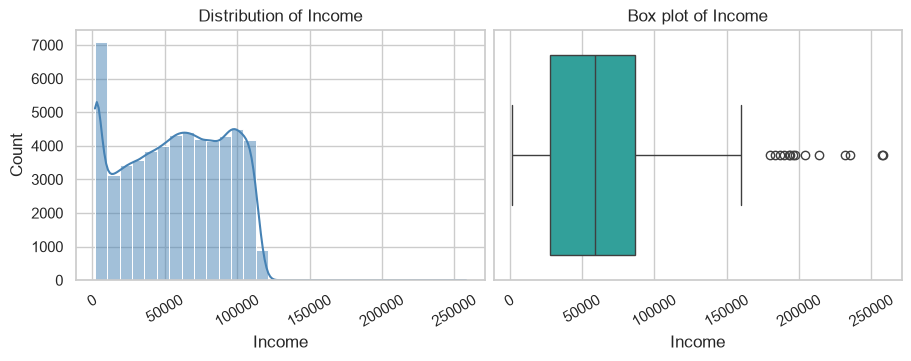

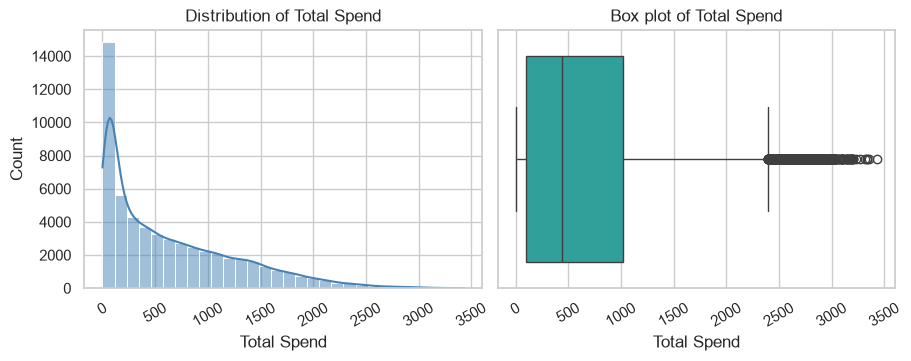

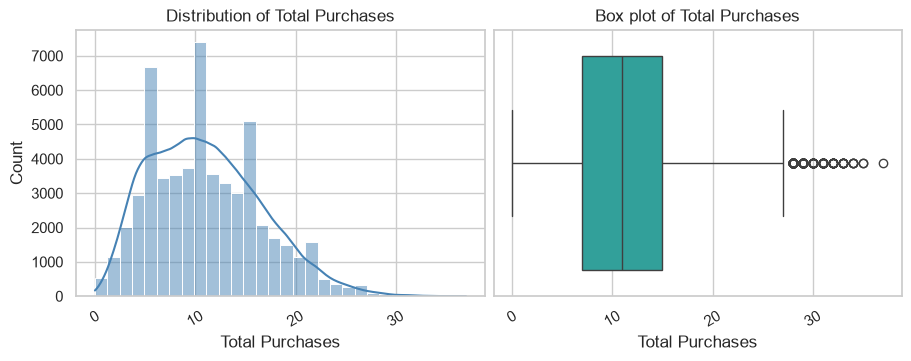

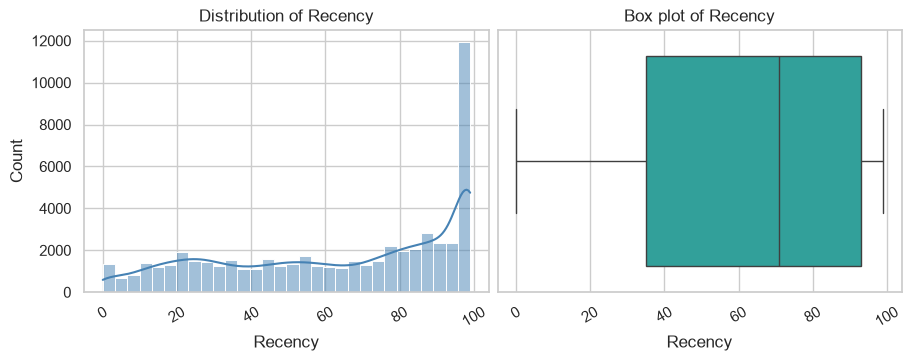

In [16]:
for column in existing_columns(df, ["Income", "Total_Spend", "Total_Purchases", "Recency"]):
    label = column.replace("_", " ")
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    sns.histplot(data=df, x=column, bins=30, kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(data=df, x=column, ax=axes[1], color="lightseagreen")
    axes[0].set(title=f"Distribution of {label}", xlabel=label)
    axes[1].set(title=f"Box plot of {label}", xlabel=label)
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=30)
    plt.show()
    plt.close(fig)



Frequency table for Education:


,Education,customer_count,percent
0,Graduation,22741,40.61
1,PhD,12581,22.47
2,Master,10530,18.80
3,2n Cycle,5966,10.65
4,Basic,4182,7.47


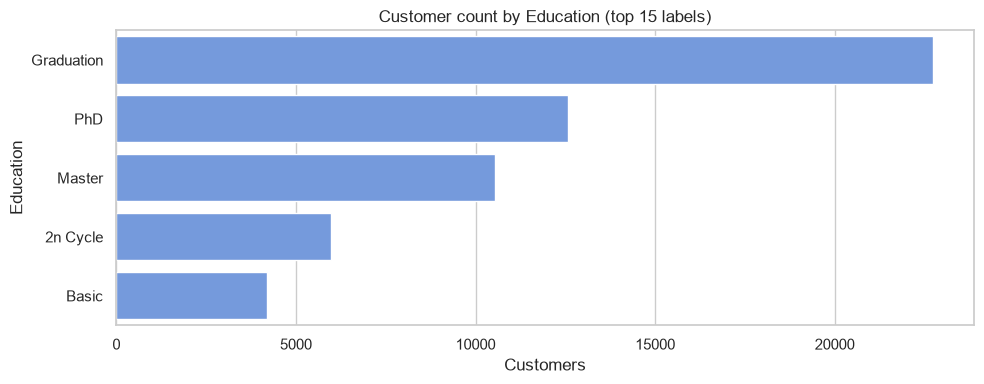

This chart shows group size. It does not show campaign success by itself.

Frequency table for Marital_Status:


,Marital_Status,customer_count,percent
0,Together,17703,31.61
1,Married,13686,24.44
2,Single,12238,21.85
3,Divorced,6459,11.53
4,Widow,3540,6.32
5,Alone,911,1.63
6,Absurd,733,1.31
7,YOLO,730,1.30


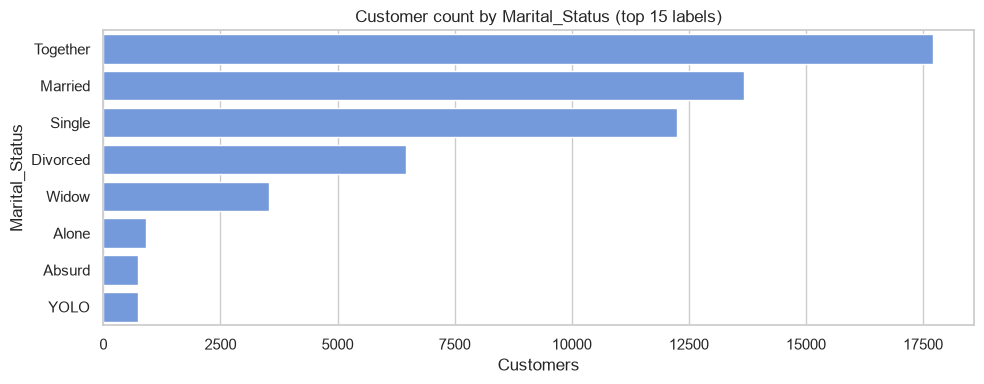

This chart shows group size. It does not show campaign success by itself.

Frequency table for Country:


,Country,customer_count,percent
0,Spain,16703,29.83
1,Canada,10746,19.19
2,Saudi Arabia,8422,15.04
3,Australia,5677,10.14
4,India,4814,8.60
5,Germany,4432,7.91
6,USA,4331,7.73
7,Mexico,875,1.56


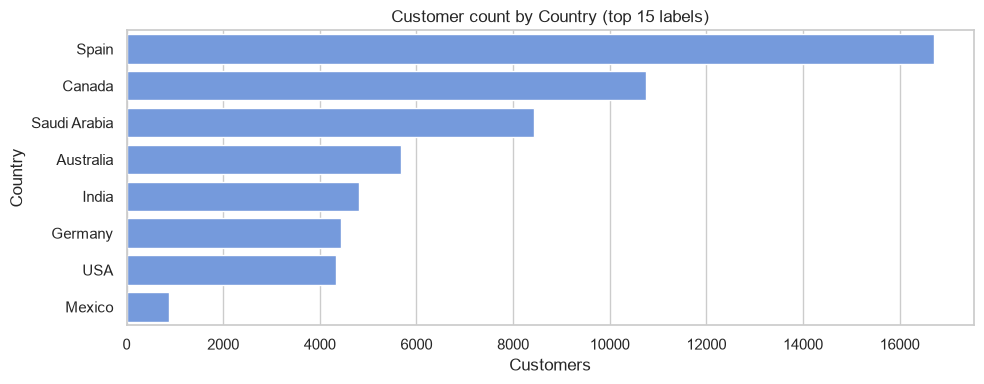

This chart shows group size. It does not show campaign success by itself.

Frequency table for Response:


,Response,customer_count,percent
0,0,47735,85.24
1,1,8265,14.76


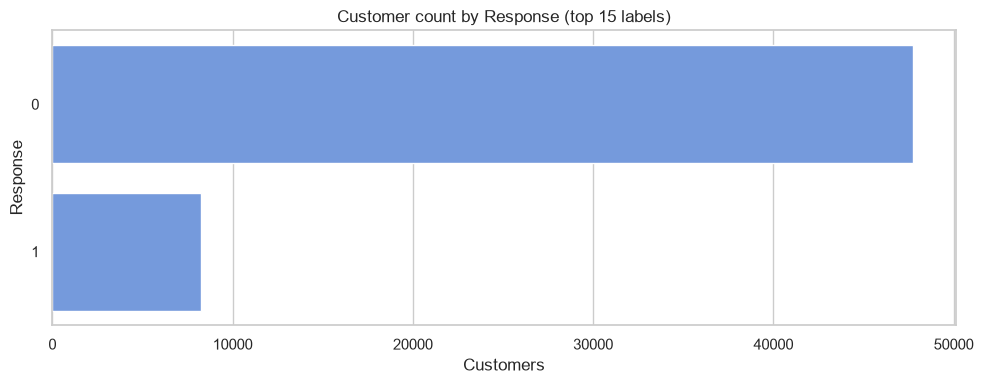

This chart shows group size. It does not show campaign success by itself.

Frequency table for Complain:


,Complain,customer_count,percent
0,0,55573,99.24
1,1,427,0.76


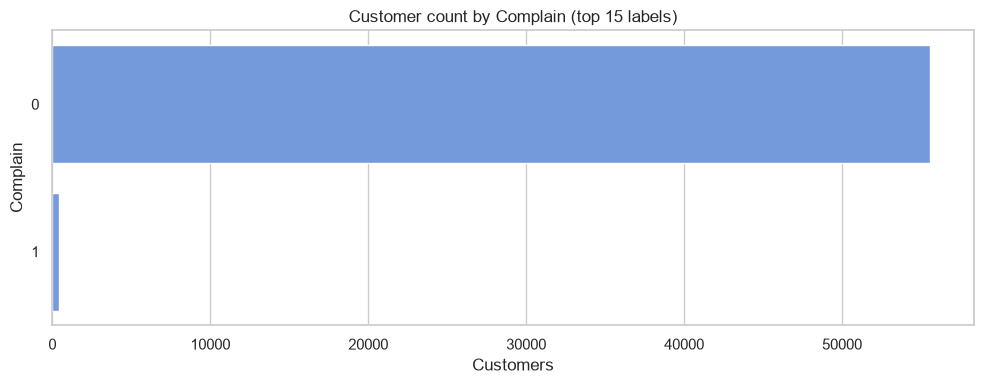

This chart shows group size. It does not show campaign success by itself.


In [17]:
category_columns = existing_columns(df, ["Education", "Marital_Status", "Country", "Response", "Complain"])
for column in category_columns:
    frequency = df[column].value_counts(dropna=False).rename_axis(column).reset_index(name="customer_count")
    frequency["percent"] = (frequency["customer_count"] / len(df) * 100).round(2)
    print(f"\nFrequency table for {column}:")
    show_table(frequency, rows=20)

    labels = df[column].value_counts(dropna=False).head(15).index
    chart_data = df[df[column].isin(labels)]
    plt.figure(figsize=(10, max(4, len(labels) * 0.35)))
    sns.countplot(data=chart_data, y=column, order=labels, color="cornflowerblue")
    plt.title(f"Customer count by {column} (top 15 labels)")
    plt.xlabel("Customers")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()
    print("This chart shows group size. It does not show campaign success by itself.")


## 11. Perform bivariate analysis

Study pairs of variables: income/spending, education/spending, and country/response. Compare rates together with group sizes.


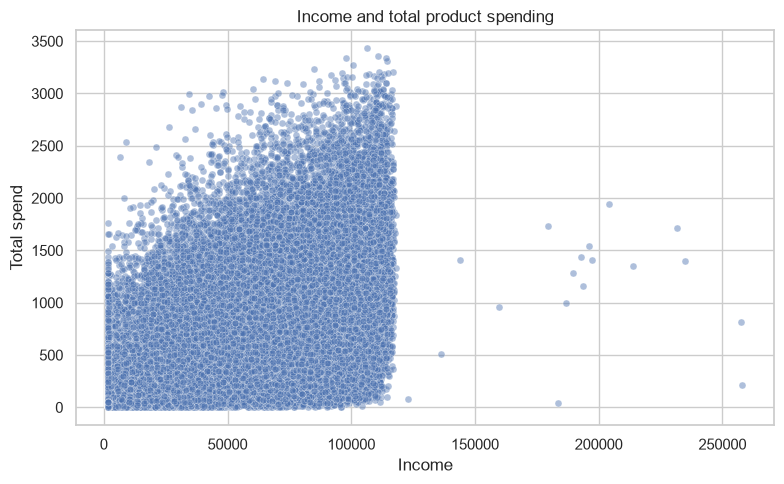

The scatter plot checks whether higher reported income tends to occur with higher spending.



Average measures by Country:


,Total_Spend,Total_Purchases,Income,Response
Country,,,,
Australia,827.38,12.21,65940.30,0.20
India,723.85,12.06,59255.55,0.19
Germany,707.24,11.68,61592.85,0.17
USA,663.88,11.56,59366.62,0.16
Saudi Arabia,654.57,11.36,61095.04,0.15
Mexico,634.14,10.80,58688.88,0.15
Canada,585.32,10.61,53425.66,0.12
Spain,557.37,10.27,52470.79,0.13


Compare group sizes before making a decision from a group average.


In [18]:
if {"Income", "Total_Spend"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="Income", y="Total_Spend", alpha=0.45, s=25)
    plt.title("Income and total product spending")
    plt.xlabel("Income")
    plt.ylabel("Total spend")
    plt.tight_layout()
    plt.show()
    print("The scatter plot checks whether higher reported income tends to occur with higher spending.")

group_column = "Country" if "Country" in df.columns else ("Education" if "Education" in df.columns else None)
summary_columns = existing_columns(df, ["Total_Spend", "Total_Purchases", "Income", "Response"])
if group_column and summary_columns:
    grouped = df.groupby(group_column, dropna=False, observed=True)[summary_columns].mean().round(2).sort_values(summary_columns[0], ascending=False)
    print(f"\nAverage measures by {group_column}:")
    show_table(grouped, rows=20)
    print("Compare group sizes before making a decision from a group average.")


,records,valid_responses,response_rate,response_percent
Country,,,,
Australia,5677,5677,0.20,20.19
India,4814,4814,0.19,18.76
Germany,4432,4432,0.17,16.81
USA,4331,4331,0.16,15.70
Mexico,875,875,0.15,15.20
Saudi Arabia,8422,8422,0.15,14.90
Spain,16703,16703,0.13,12.93
Canada,10746,10746,0.12,11.57


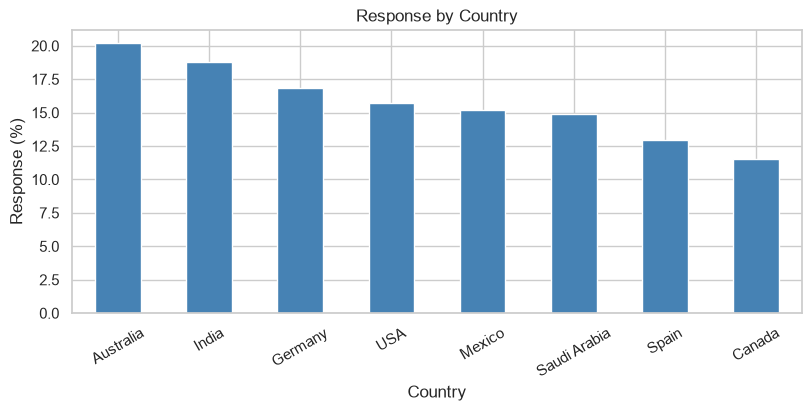

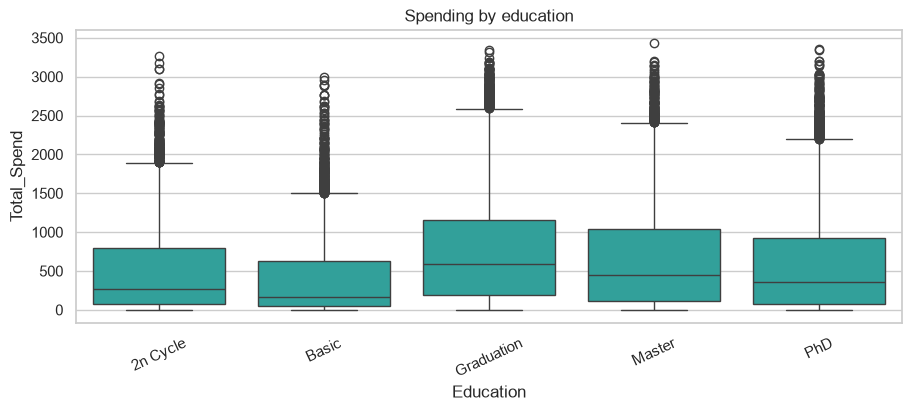

In [19]:
group_response = pd.DataFrame()
if group_column and "Response" in df:
    response_data = df[[group_column, "Response"]].copy()
    response_data["valid_response"] = response_data["Response"].where(response_data["Response"].isin([0, 1]))
    group_response = response_data.groupby(group_column, observed=True, dropna=False).agg(records=("Response", "size"), valid_responses=("valid_response", "count"), response_rate=("valid_response", "mean"))
    group_response["response_percent"] = group_response["response_rate"] * 100
    group_response = group_response.sort_values("response_rate", ascending=False)
    show_table(group_response.round(2), rows=len(group_response))
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    group_response["response_percent"].plot.bar(ax=ax, color="steelblue")
    ax.set(title=f"Response by {group_column}", ylabel="Response (%)")
    ax.tick_params(axis="x", labelrotation=30)
    plt.show()
    plt.close(fig)
if {"Education", "Total_Spend"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    sns.boxplot(data=df, x="Education", y="Total_Spend", ax=ax, color="lightseagreen")
    ax.set_title("Spending by education")
    ax.tick_params(axis="x", labelrotation=25)
    plt.show()
    plt.close(fig)


## 12. Perform multivariate analysis

Explore multiple measures using a correlation heatmap, response-colored pair plot, age/income response heatmap, and descriptive segments. Pair plots use a reproducible sample; heatmap rates require at least 30 valid responses per group.


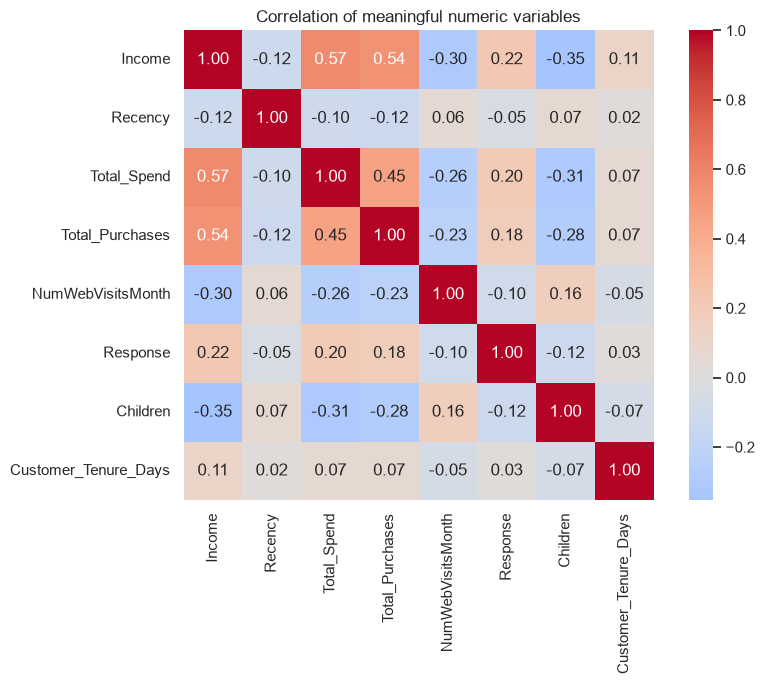

Correlation measures linear association, not proof of cause and effect. Numeric IDs are excluded.


In [20]:
correlation_columns = existing_columns(df, ["Income", "Recency", "Total_Spend", "Total_Purchases", "NumWebVisitsMonth", "Response", "Children", "Customer_Tenure_Days"])
if len(correlation_columns) >= 2:
    plt.figure(figsize=(9, 7))
    sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
    plt.title("Correlation of meaningful numeric variables")
    plt.tight_layout()
    plt.show()
    print("Correlation measures linear association, not proof of cause and effect. Numeric IDs are excluded.")


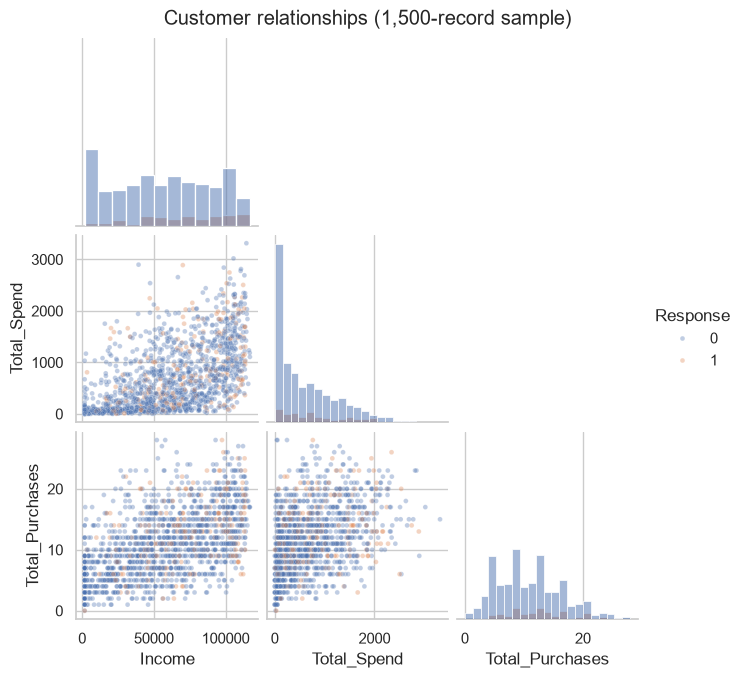

Valid response counts by age and income band:


Income_Band,Up to 25k,25k-50k,50k-75k,75k+
Age_Band,,,,
Under 30,2339,1727,1763,2456
30-39,4225,3428,3609,5225
40-49,3644,3086,3601,5316
50-59,1656,1712,2252,4311
60+,813,1013,1350,2474


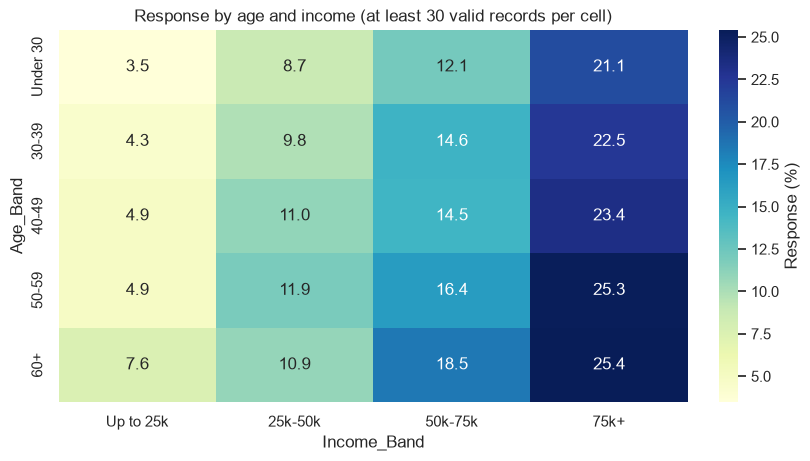

In [21]:
pair_columns = existing_columns(df, ["Income", "Total_Spend", "Total_Purchases"])
if len(pair_columns) >= 2 and "Response" in df:
    pair_data = df.loc[df["Response"].isin([0, 1]), pair_columns + ["Response"]].dropna()
    pair_data = pair_data.sample(n=min(1500, len(pair_data)), random_state=42)
    if not pair_data.empty:
        grid = sns.pairplot(pair_data, vars=pair_columns, hue="Response", diag_kind="hist", corner=True, height=2.2, plot_kws={"alpha": 0.35, "s": 12})
        grid.figure.suptitle(f"Customer relationships ({len(pair_data):,}-record sample)", y=1.02)
        plt.show()
        plt.close(grid.figure)
if {"Age_Band", "Income_Band", "Response"}.issubset(df.columns):
    band_data = df.loc[df["Response"].isin([0, 1])]
    band_summary = band_data.groupby(["Age_Band", "Income_Band"], observed=True)["Response"].agg(["count", "mean"])
    band_counts = band_summary["count"].unstack("Income_Band")
    band_rates = band_summary["mean"].unstack("Income_Band") * 100
    print("Valid response counts by age and income band:")
    show_table(band_counts, rows=len(band_counts))
    if not band_rates.empty and band_counts.ge(30).any().any():
        fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
        sns.heatmap(band_rates.where(band_counts.ge(30)), annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Response (%)"}, ax=ax)
        ax.set_title("Response by age and income (at least 30 valid records per cell)")
        plt.show()
        plt.close(fig)


### Descriptive customer segments
These rules use response as an input. Response differences between the resulting segments are therefore not independent evidence of campaign effectiveness.


Customer-segment summary:


Total_Spend          Total_Purchases       
                                count     mean           count   mean
Customer_Segment                                                     
Frequent purchasers              8525   216.46            8525  14.56
High-value non-responders       21972  1108.19           21972  13.32
High-value responders            6028  1207.11            6028  14.43
Lower activity customers        19475   122.61           19475   5.95

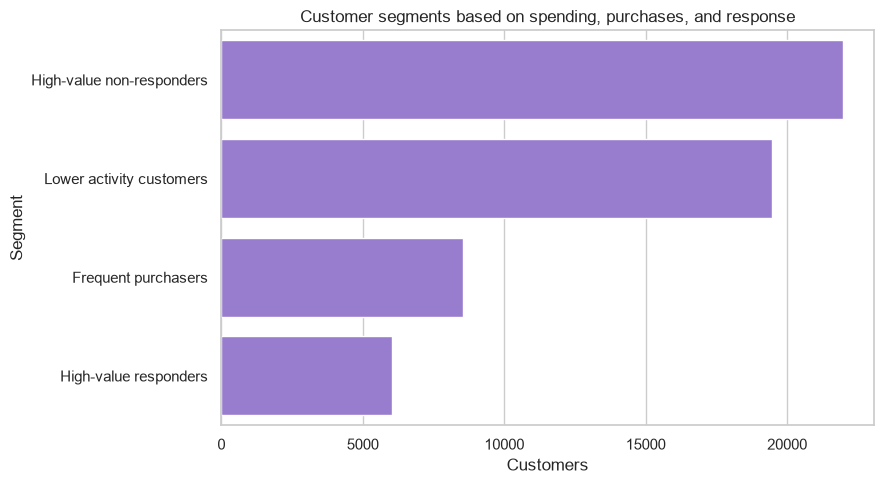

Use high-value non-responders as a starting point for a targeted campaign review.


In [22]:
# Segments are descriptive groups for EDA, not a prediction model.
if "Total_Spend" in df and df["Total_Spend"].nunique(dropna=True) >= 4:
    df["Spend_Segment"] = pd.qcut(
        df["Total_Spend"], q=4, labels=["Low spend", "Medium spend", "High spend", "Very high spend"]
    )

if {"Total_Spend", "Total_Purchases"}.issubset(df.columns):
    spend_midpoint = df["Total_Spend"].median()
    purchase_midpoint = df["Total_Purchases"].median()
    response_condition = df["Response"].eq(1) if "Response" in df else pd.Series(False, index=df.index)
    df["Customer_Segment"] = np.select(
        [
            (df["Total_Spend"] >= spend_midpoint) & response_condition,
            (df["Total_Spend"] >= spend_midpoint) & ~response_condition,
            (df["Total_Purchases"] >= purchase_midpoint),
        ],
        ["High-value responders", "High-value non-responders", "Frequent purchasers"],
        default="Lower activity customers",
    )
    segment_summary = (
        df.groupby("Customer_Segment", observed=True)
        [["Total_Spend", "Total_Purchases"]]
        .agg(["count", "mean"])
        .round(2)
    )
    print("Customer-segment summary:")
    show_table(segment_summary, rows=len(segment_summary))

    plt.figure(figsize=(9, 5))
    segment_order = df["Customer_Segment"].value_counts().index
    sns.countplot(data=df, y="Customer_Segment", order=segment_order, color="mediumpurple")
    plt.title("Customer segments based on spending, purchases, and response")
    plt.xlabel("Customers")
    plt.ylabel("Segment")
    plt.tight_layout()
    plt.show()
    print("Use high-value non-responders as a starting point for a targeted campaign review.")


## 13. Calculate business KPIs (Key Performance Indicator)

Display KPI definitions and eligible-record counts. Unique customers use distinct non-missing IDs; binary rates exclude invalid/missing flags; spending/purchase KPIs exclude missing or negative totals. Spending is not profit or attributed revenue, and ROI is not calculated without costs and attribution data.


In [23]:
kpi_rows = []
def add_kpi(metric, value, unit, eligible_records, definition):
    kpi_rows.append({"metric": metric, "value": value, "unit": unit, "eligible_records": eligible_records, "definition": definition})
add_kpi("Dataset records", len(df), "records", len(df), "All retained records")
if id_column:
    add_kpi("Unique customers", df[id_column].nunique(), "customers", int(df[id_column].notna().sum()), "Distinct non-missing IDs")
valid_spend = df["Total_Spend"].where(df["Total_Spend"].ge(0)).dropna()
valid_purchases = df["Total_Purchases"].where(df["Total_Purchases"].ge(0)).dropna()
add_kpi("Total recorded spending", valid_spend.sum(min_count=1), "currency units", len(valid_spend), "Sum of eligible Total_Spend")
add_kpi("Average spending per record", valid_spend.mean(), "currency units", len(valid_spend), "Mean of eligible Total_Spend")
add_kpi("Median spending per record", valid_spend.median(), "currency units", len(valid_spend), "Median of eligible Total_Spend")
add_kpi("Total channel purchases", valid_purchases.sum(min_count=1), "purchases", len(valid_purchases), "Web + catalog + store; excludes deal purchases")
add_kpi("Average purchases per record", valid_purchases.mean(), "purchases", len(valid_purchases), "Mean of eligible Total_Purchases")
for column, label in [("Response", "Latest campaign response rate"), ("Any_Campaign_Accepted", "Any campaign acceptance rate"), ("Complain", "Complaint rate"), ("High_Spender", "High-spender share")]:
    if column in df:
        eligible = df.loc[df[column].isin([0, 1]), column]
        add_kpi(label, eligible.mean() * 100 if len(eligible) else np.nan, "%", len(eligible), f"100 x sum({column}) / valid binary records")
if "Response" in df:
    add_kpi("Latest campaign responders", int(df["Response"].eq(1).sum()), "records", int(df["Response"].isin([0, 1]).sum()), "Response equals 1")
if "Customer_Segment" in df:
    add_kpi("High-value non-responders", int(df["Customer_Segment"].eq("High-value non-responders").sum()), "records", len(df), "At least median spend and no recorded positive response")
kpi_table = pd.DataFrame(kpi_rows)
show_table(kpi_table.round({"value": 2}), rows=len(kpi_table))
campaign_rows = []
for column in campaign_columns + existing_columns(df, ["Response"]):
    eligible = df.loc[df[column].isin([0, 1]), column]
    campaign_rows.append({"campaign": column, "valid_records": len(eligible), "accepted": int(eligible.sum()), "acceptance_percent": eligible.mean() * 100 if len(eligible) else np.nan})
print("Campaign acceptance; customers may accept multiple campaigns:")
show_table(pd.DataFrame(campaign_rows).round(2), rows=len(campaign_rows))
product_totals = df[spend_columns].where(df[spend_columns].ge(0)).sum(min_count=1).sort_values(ascending=False)
product_kpis = product_totals.rename("spending").to_frame()
product_kpis["share_percent"] = product_totals / product_totals.sum() * 100 if product_totals.sum() > 0 else np.nan
channel_totals = df[purchase_columns].where(df[purchase_columns].ge(0)).sum(min_count=1).sort_values(ascending=False)
channel_kpis = channel_totals.rename("purchases").to_frame()
channel_kpis["share_percent"] = channel_totals / channel_totals.sum() * 100 if channel_totals.sum() > 0 else np.nan
print("Product spending: each column uses available non-negative values.")
show_table(product_kpis.round(2), rows=len(product_kpis))
print("Purchase-channel mix:")
show_table(channel_kpis.round(2), rows=len(channel_kpis))


,metric,value,unit,eligible_records,definition
0,Dataset records,56000.00,records,56000,All retained records
1,Unique customers,56000.00,customers,56000,Distinct non-missing IDs
2,Total recorded spending,35858736.00,currency units,56000,Sum of eligible Total_Spend
3,Average spending per record,640.33,currency units,56000,Mean of eligible Total_Spend
4,Median spending per record,441.50,currency units,56000,Median of eligible Total_Spend
5,Total channel purchases,619699.00,purchases,56000,Web + catalog + store; excludes deal purchases
6,Average purchases per record,11.07,purchases,56000,Mean of eligible Total_Purchases
7,Latest campaign response rate,14.76,%,56000,100 x sum(Response) / valid binary records
8,Any campaign acceptance rate,36.41,%,56000,100 x sum(Any_Campaign_Accepted) / valid binar...
9,Complaint rate,0.76,%,56000,100 x sum(Complain) / valid binary records


Campaign acceptance; customers may accept multiple campaigns:


,campaign,valid_records,accepted,acceptance_percent
0,AcceptedCmp1,56000,7529,13.44
1,AcceptedCmp2,56000,807,1.44
2,AcceptedCmp3,56000,3494,6.24
3,AcceptedCmp4,56000,3182,5.68
4,AcceptedCmp5,56000,2557,4.57
5,Response,56000,8265,14.76


Product spending: each column uses available non-negative values.


,spending,share_percent
MntMeatProducts,15024465,41.90
MntWines,13830963,38.57
MntFishProducts,2861473,7.98
MntGoldProds,1981595,5.53
MntSweetProducts,1255691,3.50
MntFruits,904549,2.52


Purchase-channel mix:


,purchases,share_percent
NumStorePurchases,263559,42.53
NumWebPurchases,237938,38.40
NumCatalogPurchases,118202,19.07


## 14. Summarize findings

Communicate computed findings, limitations, and business review priorities, then export the enriched data.


In [24]:
findings = [
    f"Analyzed {len(df):,} records and {len(raw.columns)} source columns; all source rows retained.",
    f"Source quality: {int(raw.isna().sum().sum()):,} missing cells and {int(raw.duplicated().sum()):,} exact duplicate rows.",
    f"Invalid-value checks flagged {int(invalid_row_mask.sum()):,} records.",
    f"Total recorded spending: {valid_spend.sum():,.2f}; mean {valid_spend.mean():,.2f} and median {valid_spend.median():,.2f} per eligible record.",
]
if "Response" in df:
    valid_response = df.loc[df["Response"].isin([0, 1]), "Response"]
    findings.append(f"Latest campaign response: {valid_response.mean():.2%} ({int(valid_response.sum()):,} of {len(valid_response):,} eligible records).")
if not product_kpis.empty:
    findings.append(f"Largest spending category: {product_kpis.index[0]} ({product_kpis.iloc[0]['share_percent']:.2f}% of recorded product spending).")
if not channel_kpis.empty:
    findings.append(f"Largest purchase channel: {channel_kpis.index[0]} ({channel_kpis.iloc[0]['share_percent']:.2f}% of channel purchases).")
if not group_response.empty:
    supported = group_response.loc[group_response["valid_responses"].ge(30)].dropna(subset=["response_rate"])
    if not supported.empty:
        findings.append(f"Highest observed response by {group_column}: {supported.index[0]} ({supported.iloc[0]['response_rate']:.2%}; {int(supported.iloc[0]['valid_responses']):,} valid records). Not adjusted for customer mix.")
if not outlier_summary.empty:
    top = outlier_summary.iloc[0]
    findings.append(f"Most IQR outlier flags: {top['column']} ({int(top['outlier_count']):,}); retained for review.")
if {"Income", "Total_Spend"}.issubset(df.columns):
    findings.append(f"Income/spending Pearson correlation: {df['Income'].corr(df['Total_Spend']):.3f}; association is not causation.")
for number, finding in enumerate(findings, 1):
    print(f"{number}. {finding}")
print("\nNext steps:")
print("- Review high-value non-responders for targeted campaign experiments.")
print("- Evaluate response rates together with group sizes before selecting audiences.")
print("- Investigate extreme values before choosing any outlier treatment.")
print("- Obtain campaign costs and attributed revenue before estimating ROI.")


1. Analyzed 56,000 records and 28 source columns; all source rows retained.


2. Source quality: 0 missing cells and 0 exact duplicate rows.
3. Invalid-value checks flagged 0 records.
4. Total recorded spending: 35,858,736.00; mean 640.33 and median 441.50 per eligible record.
5. Latest campaign response: 14.76% (8,265 of 56,000 eligible records).
6. Largest spending category: MntMeatProducts (41.90% of recorded product spending).
7. Largest purchase channel: NumStorePurchases (42.53% of channel purchases).
8. Highest observed response by Country: Australia (20.19%; 5,677 valid records). Not adjusted for customer mix.
9. Most IQR outlier flags: MntFruits (7,968); retained for review.
10. Income/spending Pearson correlation: 0.573; association is not causation.

Next steps:
- Review high-value non-responders for targeted campaign experiments.
- Evaluate response rates together with group sizes before selecting audiences.
- Investigate extreme values before choosing any outlier treatment.
- Obtain campaign costs and attributed revenue before estimating ROI.


### Export and download the enriched data


In [25]:
# df has trimmed text, converted types, and derived features, while preserving all rows.
df.to_csv(OUTPUT_FILE, index=False)
print(f"Exported {len(df):,} rows to {OUTPUT_FILE.name}")


Exported 56,000 rows to marketing_campaign_data_cleaned.csv


In [26]:
try:
    from google.colab import files
except ImportError:
    print(f"Cleaned CSV saved as {OUTPUT_FILE.name}.")
else:
    files.download(str(OUTPUT_FILE))


Cleaned CSV saved as marketing_campaign_data_cleaned.csv.


### Optional MySQL load
Upload `database.py` and `config.py` and configure the DB environment variables (or private `.env`) before enabling `STORE_IN_DATABASE`. The MySQL server must be reachable from Colab; localhost there is not your computer. The CSV analysis works without a database.


In [27]:
if STORE_IN_DATABASE:
    from database import store_cleaned_data

    inserted_rows, total_rows = store_cleaned_data(df)
    print(f"MySQL load complete: {inserted_rows:,} new rows; {total_rows:,} rows in marketing_campaign_data.")
else:
    print("MySQL load skipped. Set STORE_IN_DATABASE = True after reviewing the EDA output.")


MySQL load skipped. Set STORE_IN_DATABASE = True after reviewing the EDA output.
